In [1]:
import random, time
from dataclasses import dataclass, field
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
# CONFIGURACIÓN
CARPETA = r"./dataset_manzanas"
SUBCARPETA_IMAGENES = "imagenes"
SUBCARPETA_MASCARAS = "mascaras"
SEMILLA = 42
FRAC_AJUSTE = 0.7 # 70 % ajuste de parámetros / 30 % test final

In [3]:
# Lista de nombres de archivo (las máscaras se llaman igual que las imágenes)
nombres = sorted(os.listdir(os.path.join(CARPETA, SUBCARPETA_IMAGENES)))

# División ajuste / test, reproducible gracias a la semilla
random.seed(SEMILLA)
random.shuffle(nombres)
corte = int(len(nombres) * FRAC_AJUSTE)
ajuste = nombres[:corte]
test = nombres[corte:]

def cargar_par(nombre):
    """Devuelve la imagen (BGR) y su máscara binaria (0/1)."""
    img = cv.imread(os.path.join(CARPETA, SUBCARPETA_IMAGENES, nombre))
    mascara = cv.imread(os.path.join(CARPETA, SUBCARPETA_MASCARAS, nombre), cv.IMREAD_GRAYSCALE)
    return img, (mascara > 127).astype(np.uint8)

print(len(nombres), "imágenes |", len(ajuste), "ajuste |", len(test), "test")

100 imágenes | 70 ajuste | 30 test


In [4]:
# Funcion auxiliar para evitar divisiones por cero
def _div(a, b):
    return a / b if b > 0 else 0.0

def metricas_pixel(pred, gt):
    p = pred > 0
    g = gt > 0
    TP = int(np.sum(p & g))      # manzana detectada como manzana
    TN = int(np.sum(~p & ~g))    # fondo detectado como fondo
    FP = int(np.sum(p & ~g))     # fondo marcado como manzana
    FN = int(np.sum(~p & g))     # manzana que se nos escapa
    return {"TP": TP, "TN": TN, "FP": FP, "FN": FN,
            "exactitud": _div(TP + TN, p.size),
            "precision": _div(TP, TP + FP),
            "recall": _div(TP, TP + FN),
            "iou": _div(TP, TP + FP + FN),
            "dice": _div(2 * TP, 2 * TP + FP + FN)}

def metricas_objeto(pred, gt, iou_min=0.5, area_min=30):
    """Cuenta manzanas. iou_min = fracción mínima de solape para dar por buena una detección."""
    p = (pred > 0).astype(np.uint8)
    g = (gt > 0).astype(np.uint8)
    n_p, lab_p = cv.connectedComponents(p)     # la etiqueta 0 es el fondo
    n_g, lab_g = cv.connectedComponents(g)

    # Manzanas reales: está detectada si la predicción cubre al menos iou_min de su área
    n_gt, detectadas = 0, 0
    for i in range(1, n_g):
        region = lab_g == i
        if region.sum() < area_min:
            continue
        n_gt += 1
        if p[region].mean() >= iou_min:
            detectadas += 1

    # Objetos predichos: es falso positivo si cae mayormente sobre fondo
    n_pred, falsos = 0, 0
    for i in range(1, n_p):
        region = lab_p == i
        if region.sum() < area_min:
            continue
        n_pred += 1
        if g[region].mean() < iou_min:
            falsos += 1

    precision = _div(n_pred - falsos, n_pred)
    recall = _div(detectadas, n_gt)
    return {"n_gt": n_gt, "n_pred": n_pred,
            "obj_TP": detectadas, "obj_FP": falsos, "obj_FN": n_gt - detectadas,
            "obj_precision": precision, "obj_recall": recall,
            "obj_f1": _div(2 * precision * recall, precision + recall),
            "error_conteo": n_pred - n_gt}

In [5]:
# ---------- Preprocesado: reciben una imagen y devuelven una imagen ----------
def mediana(img, k=5):
    return cv.medianBlur(img, k)                  # k debe ser impar

def gauss(img, k=5, sigma=1.5):
    return cv.GaussianBlur(img, (k, k), sigma)    # k debe ser impar

def clahe_l(img, clip=2.0, tile=8):
    """CLAHE sobre la luminosidad (canal L de Lab): corrige luz desigual."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    clahe = cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv.cvtColor(lab, cv.COLOR_LAB2BGR)

# ---------- Segmentación: recibe una imagen y devuelve una máscara ----------
def umbral_hsv(img, h=(22, 40), s=(70, 255), v=(90, 255)):
    """Método base: rango de color en HSV (valores de partida, SIN ajustar)."""
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    return cv.inRange(hsv, (h[0], s[0], v[0]), (h[1], s[1], v[1]))

# ---------- Postprocesado: reciben máscara (y la imagen) y devuelven máscara ----------
def abrir_cerrar(mascara, img, k_abrir=3, k_cerrar=5):
    m = (mascara > 0).astype(np.uint8) * 255
    k1 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_abrir, k_abrir))
    k2 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k_cerrar, k_cerrar))
    m = cv.morphologyEx(m, cv.MORPH_OPEN, k1)      # quita motas pequeñas
    m = cv.morphologyEx(m, cv.MORPH_CLOSE, k2)     # rellena huecos
    return m

def filtrar_area(mascara, img, area_min=40, area_max=None):
    m = (mascara > 0).astype(np.uint8)
    n, etiquetas, stats, _ = cv.connectedComponentsWithStats(m, connectivity=8)
    salida = np.zeros_like(m)
    for i in range(1, n):                          # la etiqueta 0 es el fondo
        area = stats[i, cv.CC_STAT_AREA]
        if area >= area_min and (area_max is None or area <= area_max):
            salida[etiquetas == i] = 255
    return salida

# Diccionario para llamar a cada función por su nombre
CATALOGO = {"mediana": mediana, "gauss": gauss, "clahe_l": clahe_l,
            "umbral_hsv": umbral_hsv,
            "abrir_cerrar": abrir_cerrar, "filtrar_area": filtrar_area}

class Metodo:
    """Un método = preprocesados -> segmentador -> postprocesados.
    Cada etapa se escribe como (nombre, {parámetros}). Se usa como una función: metodo(img) -> máscara."""
    def __init__(self, nombre, seg, preproc=None, post=None):
        self.nombre = nombre
        self.seg = seg
        self.preproc = preproc or []
        self.post = post or []

    def __call__(self, img):
        x = img
        for nombre, params in self.preproc:
            x = CATALOGO[nombre](x, **params)
        nombre, params = self.seg
        mascara = CATALOGO[nombre](x, **params)
        for nombre, params in self.post:
            mascara = CATALOGO[nombre](mascara, img, **params)
        return (mascara > 0).astype(np.uint8)

print("Componentes disponibles:", list(CATALOGO))

Componentes disponibles: ['mediana', 'gauss', 'clahe_l', 'umbral_hsv', 'abrir_cerrar', 'filtrar_area']


In [6]:
def evaluar(metodo, nombres):
    """Aplica un método a cada imagen y devuelve una tabla (una fila por imagen)."""
    filas = []
    for nombre in nombres:
        img, gt = cargar_par(nombre)
        pred = metodo(img)
        fila = {"metodo": metodo.nombre, "id": nombre}
        fila.update(metricas_pixel(pred, gt))
        fila.update(metricas_objeto(pred, gt))
        fila["error_abs"] = abs(fila["error_conteo"])    # error de conteo sin signo
        filas.append(fila)
    return pd.DataFrame(filas)

def comparar(metodos, nombres):
    """Evalúa varios métodos y junta los resultados en una sola tabla."""
    tablas = [evaluar(m, nombres) for m in metodos]
    return pd.concat(tablas, ignore_index=True)

def resumen(tabla):
    """Media por método, ordenada de mejor a peor Dice."""
    columnas = ["iou", "dice", "precision", "recall", "obj_f1", "error_conteo", "error_abs"]
    return tabla.groupby("metodo")[columnas].mean().sort_values("dice", ascending=False)

def mostrar(img, pred, gt, titulo=""):
    # Mapa de errores: verde = acierto, rojo = falso positivo, azul = manzana perdida
    errores = np.zeros((*gt.shape, 3), dtype=np.uint8)
    errores[(pred > 0) & (gt > 0)] = (0, 255, 0)
    errores[(pred > 0) & (gt == 0)] = (255, 0, 0)
    errores[(pred == 0) & (gt > 0)] = (0, 0, 255)

    fig, ax = plt.subplots(1, 3, figsize=(14, 8))
    ax[0].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); ax[0].set_title("Original")
    ax[1].imshow(gt, cmap="gray"); ax[1].set_title("Máscara real")
    ax[2].imshow(errores); ax[2].set_title("Verde=acierto  Rojo=falso+  Azul=perdida")
    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.show()

# --- Prueba con el método base ---
m_base = Metodo("HSV base", seg=("umbral_hsv", {}))
tabla = comparar([m_base], ajuste[:3])
print(resumen(tabla).round(3).to_string())

            iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                    
HSV base  0.142  0.234      0.151   0.583    0.14       143.333    143.333


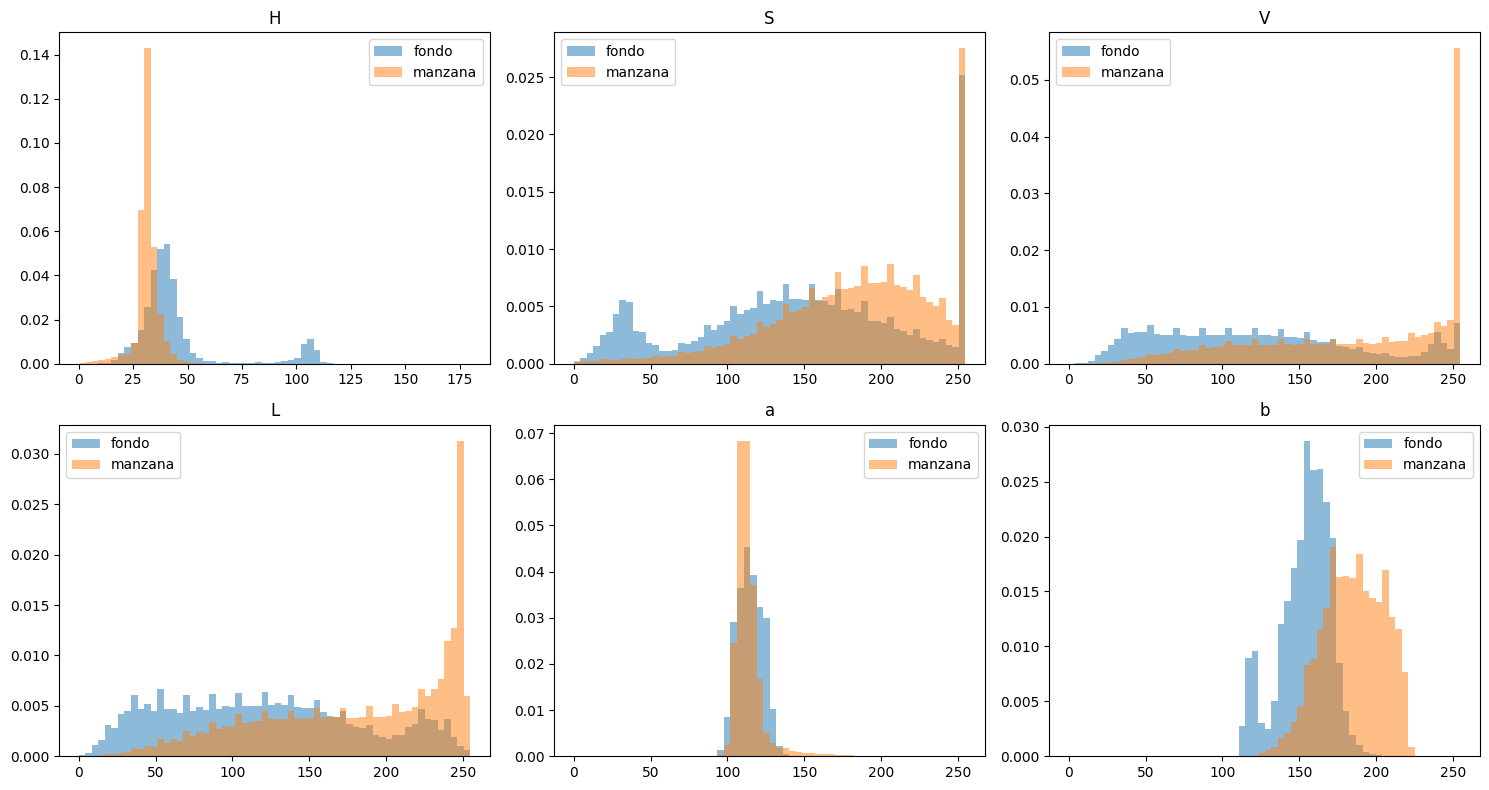

H: manzana   31.1 ±   7.2 | fondo   44.7 ±  21.9
S: manzana  183.5 ±  52.7 | fondo  146.8 ±  68.3
V: manzana  185.3 ±  64.6 | fondo  122.5 ±  64.6
L: manzana  180.3 ±  61.5 | fondo  120.2 ±  63.0
a: manzana  113.5 ±   9.4 | fondo  114.8 ±   8.2
b: manzana  184.8 ±  19.9 | fondo  153.8 ±  16.7


In [7]:
manzana = []   # cada fila: [H, S, V, L, a, b] de un píxel de manzana
fondo = []     # lo mismo para píxeles de fondo

for nombre in ajuste:
    img, gt = cargar_par(nombre)
    hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    pixeles = np.dstack([hsv, lab]).reshape(-1, 6)
    etiqueta = gt.reshape(-1)
    manzana.append(pixeles[etiqueta == 1][::5])    # 1 de cada 5 píxeles
    fondo.append(pixeles[etiqueta == 0][::50])     # 1 de cada 50 (hay muchos más)

manzana = np.vstack(manzana)
fondo = np.vstack(fondo)

canales = ["H", "S", "V", "L", "a", "b"]

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i, c in enumerate(canales):
    rango = (0, 180) if c == "H" else (0, 255)    # en OpenCV, H va de 0 a 180
    ax[i].hist(fondo[:, i], bins=60, range=rango, density=True, alpha=0.5, label="fondo")
    ax[i].hist(manzana[:, i], bins=60, range=rango, density=True, alpha=0.5, label="manzana")
    ax[i].set_title(c)
    ax[i].legend()
plt.tight_layout()
plt.show()

for i, c in enumerate(canales):
    print(f"{c}: manzana {manzana[:, i].mean():6.1f} ± {manzana[:, i].std():5.1f} | "
          f"fondo {fondo[:, i].mean():6.1f} ± {fondo[:, i].std():5.1f}")

In [8]:
# Cada píxel de manzana muestreado representa 5 reales, y cada píxel de fondo, 50
peso_manzana = 5
peso_fondo = 50

for i, c in enumerate(canales):
    # Cuántos píxeles hay con cada valor (0-255), ya ponderados
    hist_m = np.bincount(manzana[:, i], minlength=256) * peso_manzana
    hist_f = np.bincount(fondo[:, i], minlength=256) * peso_fondo
    # Sumas acumuladas: permiten contar píxeles en un rango [lo, hi] de golpe
    acum_m = np.concatenate([[0], np.cumsum(hist_m)])
    acum_f = np.concatenate([[0], np.cumsum(hist_f)])
    total_m = acum_m[-1]

    mejor_dice, mejor_rango = 0, None
    for lo in range(256):
        for hi in range(lo, 256):
            TP = acum_m[hi + 1] - acum_m[lo]      # manzana dentro del rango
            FP = acum_f[hi + 1] - acum_f[lo]      # fondo dentro del rango
            FN = total_m - TP                     # manzana fuera del rango
            dice = 2 * TP / (2 * TP + FP + FN)
            if dice > mejor_dice:
                mejor_dice, mejor_rango = dice, (lo, hi)

    print(f"{c}: mejor rango {mejor_rango}  ->  Dice = {mejor_dice:.3f}")

H: mejor rango (29, 31)  ->  Dice = 0.326
S: mejor rango (192, 254)  ->  Dice = 0.156
V: mejor rango (248, 255)  ->  Dice = 0.253
L: mejor rango (241, 253)  ->  Dice = 0.287
a: mejor rango (107, 112)  ->  Dice = 0.133
b: mejor rango (185, 223)  ->  Dice = 0.581


In [9]:
def umbral_b(img, lo=185, hi=255):
    """Umbral sobre el canal b de Lab (azul↔amarillo): las manzanas son amarillo-verdosas."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return cv.inRange(lab[:, :, 2], lo, hi)

CATALOGO["umbral_b"] = umbral_b      # lo añadimos al diccionario de componentes

m_base = Metodo("HSV base", seg=("umbral_hsv", {}))
m_b = Metodo("b solo", seg=("umbral_b", {}))
m_b_med = Metodo("b + mediana", preproc=[("mediana", {"k": 5})], seg=("umbral_b", {}))
m_b_post = Metodo("b + mediana + morfología",
                  preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {}),
                  post=[("abrir_cerrar", {}), ("filtrar_area", {"area_min": 40})])

tabla = comparar([m_base, m_b, m_b_med, m_b_post], ajuste)
print(resumen(tabla).round(3).to_string())

                            iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                                    
b + mediana + morfología  0.350  0.475      0.585   0.423   0.436        29.757     31.071
b + mediana               0.345  0.471      0.570   0.426   0.423        44.686     45.286
b solo                    0.337  0.463      0.570   0.413   0.411        52.871     53.386
HSV base                  0.098  0.172      0.101   0.660   0.064       147.100    147.100


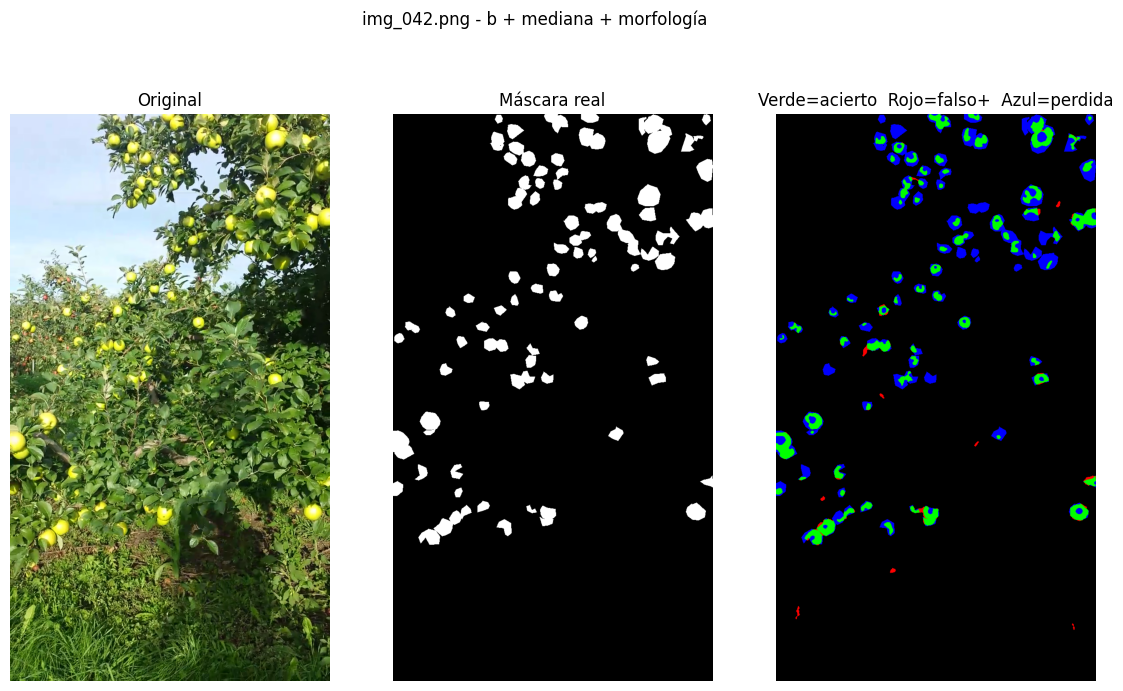

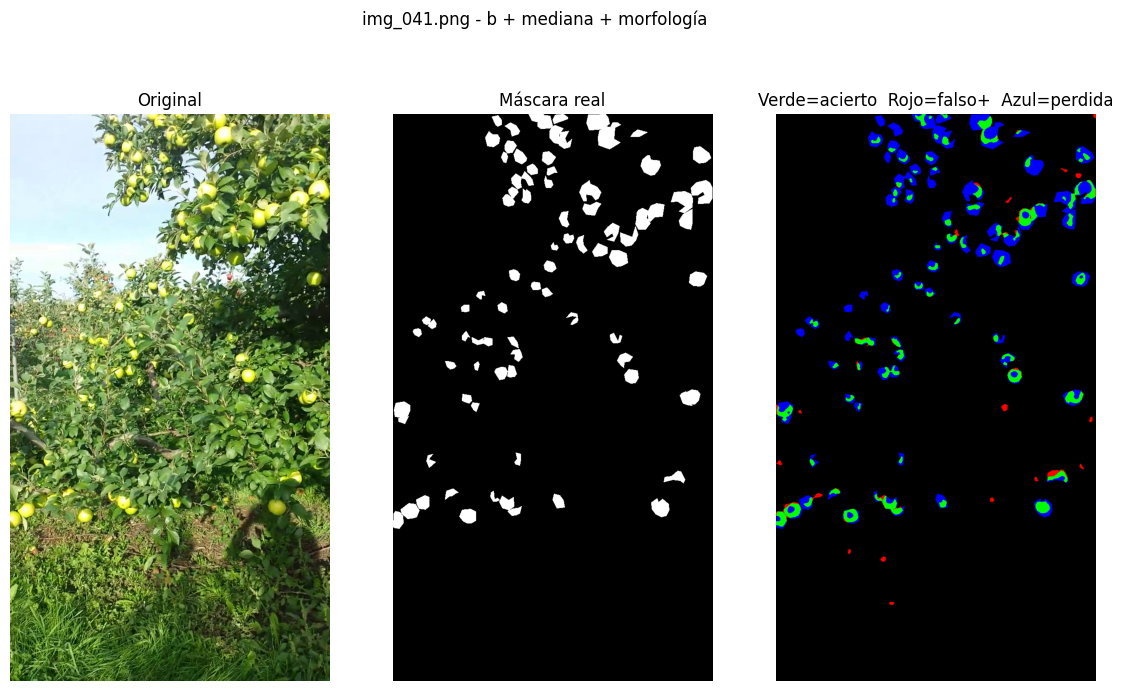

In [10]:
for nombre in ajuste[:2]:
    img, gt = cargar_par(nombre)
    pred = m_b_post(img)
    mostrar(img, pred, gt, nombre + " - b + mediana + morfología")

In [11]:
def rellenar_huecos(mascara, img):
    """Rellena los huecos interiores de cada mancha (p. ej. el brillo en el centro de una manzana)."""
    m = (mascara > 0).astype(np.uint8)
    contornos, _ = cv.findContours(m, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    salida = np.zeros_like(m)
    cv.drawContours(salida, contornos, -1, 255, cv.FILLED)
    return salida

CATALOGO["rellenar_huecos"] = rellenar_huecos

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [m_b_post]    # referencia: b=185 sin rellenar huecos
for lo in [185, 175, 165, 155]:
    metodos.append(Metodo(f"b>={lo} + relleno",
                          preproc=[("mediana", {"k": 5})],
                          seg=("umbral_b", {"lo": lo}),
                          post=post_basico))

tabla = comparar(metodos, ajuste[:20])    # 20 imágenes para ir rápido
print(resumen(tabla).round(3).to_string())

                            iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                                    
b>=185 + relleno          0.350  0.468      0.590   0.416   0.423         27.80      31.60
b + mediana + morfología  0.336  0.455      0.586   0.400   0.420         27.80      31.60
b>=175 + relleno          0.274  0.398      0.324   0.620   0.300        138.90     138.90
b>=165 + relleno          0.117  0.201      0.119   0.837   0.160         89.25      89.25
b>=155 + relleno          0.066  0.121      0.066   0.975   0.120        -12.60      23.70


In [12]:
def adaptativo_b(img, bloque=51, c=10, minimo=150):
    """Umbral LOCAL sobre b: el píxel debe superar en 'c' la media de su entorno (bloque x bloque).
    'minimo' evita que zonas oscuras o grises (con b bajo) cuenten como manzana."""
    b = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 2]
    local = cv.adaptiveThreshold(b, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, bloque, -c)
    return ((local > 0) & (b >= minimo)).astype(np.uint8) * 255

CATALOGO["adaptativo_b"] = adaptativo_b

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

# Referencia: el mejor método global hasta ahora
metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico)]

for bloque in [51, 151]:
    for c in [10, 20]:
        metodos.append(Metodo(f"adaptativo bloque={bloque} c={c}",
                              preproc=[("mediana", {"k": 5})],
                              seg=("adaptativo_b", {"bloque": bloque, "c": c}),
                              post=post_basico))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

                              iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                                      
b>=185 global               0.350  0.468      0.590   0.416   0.423         27.80      31.60
adaptativo bloque=151 c=20  0.321  0.440      0.556   0.379   0.390         48.85      49.65
adaptativo bloque=51 c=10   0.259  0.380      0.436   0.362   0.279        163.25     163.25
adaptativo bloque=151 c=10  0.249  0.371      0.291   0.579   0.245        239.55     239.55
adaptativo bloque=51 c=20   0.122  0.204      0.608   0.125   0.098          3.55      12.95


- El adaptativo no supera al global. El mejor adaptativo (bloque 151, c=20) queda en Dice 0,440 frente a 0,468 del global, y con peor error de conteo (49,7 frente a 31,6). Es un resultado válido para la memoria: un umbral local no ayuda aquí. Probablemente porque en estas imágenes las manzanas están rodeadas de hojas con colores muy variables, y la media local no es un buen punto de comparación.
- Cuidado con bloque=51, c=20. Su error_conteo es solo 3,55 y su precisión 0,608, la más alta de la tabla. Pero el recall es 0,125 y el obj_f1 0,098: detecta muy pocas manzanas, y por eso comete pocos errores de conteo. Es la misma trampa de antes: un número bueno aislado que oculta un método que apenas funciona.
- Conclusión parcial: con un único canal de color (global o local) parece haber un techo en torno a Dice ≈ 0,47. Para pasar de ahí hay que usar más información. El siguiente paso lógico es combinar b con el brillo, porque en las gráficas las manzanas eran más claras que las hojas (L ≈ 180 frente a 120), y eso puede permitir bajar el umbral de b sin dejar pasar las hojas oscuras.

In [13]:
peso_m, peso_f = 5, 50       # cada píxel muestreado de manzana vale 5 reales; de fondo, 50
resultados = []
for b_lo in range(150, 201, 5):
    for L_lo in range(100, 251, 10):
        dentro_m = (manzana[:, 5] >= b_lo) & (manzana[:, 3] >= L_lo)    # columna 5 = b, columna 3 = L
        dentro_f = (fondo[:, 5] >= b_lo) & (fondo[:, 3] >= L_lo)
        TP = dentro_m.sum() * peso_m
        FP = dentro_f.sum() * peso_f
        FN = (len(manzana) - dentro_m.sum()) * peso_m
        resultados.append((2 * TP / (2 * TP + FP + FN), b_lo, L_lo))

resultados.sort(reverse=True)
print("Mejores combinaciones (Dice por píxel, con muestras):")
for dice, b_lo, L_lo in resultados[:5]:
    print(f"  b >= {b_lo}, L >= {L_lo}  ->  Dice = {dice:.3f}")

# --- Evaluar la mejor combinación como método real ---
def umbral_bL(img, b_lo=185, L_lo=0):
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)
    return ((lab[:, :, 2] >= b_lo) & (lab[:, :, 0] >= L_lo)).astype(np.uint8) * 255

CATALOGO["umbral_bL"] = umbral_bL

_, b_mejor, L_mejor = resultados[0]
post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico),
           Metodo(f"b>={b_mejor} + L>={L_mejor}", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_bL", {"b_lo": b_mejor, "L_lo": L_mejor}), post=post_basico)]

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

Mejores combinaciones (Dice por píxel, con muestras):
  b >= 185, L >= 120  ->  Dice = 0.581
  b >= 185, L >= 110  ->  Dice = 0.581
  b >= 185, L >= 100  ->  Dice = 0.581
  b >= 185, L >= 130  ->  Dice = 0.581
  b >= 185, L >= 140  ->  Dice = 0.578
                  iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                          
b>=185 + L>=120  0.35  0.468       0.59   0.416   0.423          27.8       31.6
b>=185 global    0.35  0.468       0.59   0.416   0.423          27.8       31.6


- El brillo no aporta nada. Las cinco mejores combinaciones tienen el mismo Dice (0,581) que b solo, y la tabla real da exactamente los mismos números que “b>=185 global”. Casi cualquier píxel con b ≥ 185 ya es claro (L > 100), así que el filtro de L no descarta nada que importe. La hipótesis era razonable y salió negativa, y eso también sirve para la memoria.
- Un umbral de color tiene un techo. Ya probamos b solo, el cambio de umbral, el umbral local y b+L. Todos acaban en Dice ≈ 0,47 sobre imágenes reales. Todos tienen algo en común: trazan una frontera “recta” en el espacio de color, y las hojas amarillentas y las manzanas en sombra se solapan en color.
- Qué probar ahora: un modelo de mezcla gaussiana (GMM), que está en la teoría. Un GMM agrupa los píxeles en varias “nubes” de color con forma y orientación propias (no solo rectángulos), y se ajusta a cada imagen por separado, así que se adapta a la luz de cada foto. Es el primer método del grupo de clustering que anoté.

In [14]:
from sklearn.mixture import GaussianMixture    # si falla: pip install scikit-learn

def gmm_color(img, k=4, muestra=20000):
    """Ajusta un GMM de k componentes al color (L,a,b) de ESTA imagen.
    La componente con mayor b medio (la más amarilla) se toma como manzana."""
    lab = cv.cvtColor(img, cv.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    azar = np.random.RandomState(0)
    submuestra = lab[azar.choice(len(lab), muestra, replace=False)]   # ajustar con todos los píxeles sería lento
    gmm = GaussianMixture(n_components=k, random_state=0).fit(submuestra)
    componente_manzana = np.argmax(gmm.means_[:, 2])                  # columna 2 = b
    etiquetas = gmm.predict(lab)
    return (etiquetas == componente_manzana).reshape(img.shape[:2]).astype(np.uint8) * 255

CATALOGO["gmm_color"] = gmm_color

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]

metodos = [Metodo("b>=185 global", preproc=[("mediana", {"k": 5})],
                  seg=("umbral_b", {"lo": 185}), post=post_basico)]
for k in [3, 4, 6]:
    metodos.append(Metodo(f"GMM k={k}", preproc=[("mediana", {"k": 5})],
                          seg=("gmm_color", {"k": k}), post=post_basico))

tabla = comparar(metodos, ajuste[:10])     # 10 imágenes: el GMM es más lento
print(resumen(tabla).round(3).to_string())

c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pausa\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, c

                 iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                         
b>=185 global  0.363  0.485      0.602   0.433   0.434          27.0       29.4
GMM k=6        0.294  0.396      0.495   0.357   0.391          90.9      101.3
GMM k=4        0.093  0.157      0.103   0.563   0.139          82.3       82.3
GMM k=3        0.072  0.131      0.074   0.846   0.057          39.6       50.6


Ningún GMM supera al umbral de b. La referencia saca Dice 0,485 en estas 10 imágenes, y el mejor GMM (k=6) 0,396, con peor error de conteo (101 frente a 29).
El patrón confirma lo que sospechábamos. Con k=3 y k=4 la componente “más amarilla” absorbe también hojas claras: recall alto (0,85) y precisión muy baja (0,07-0,10). Con k=6 el modelo separa mejor, pero se queda corto.
Conclusión para la memoria: clustering de color por imagen no mejora al umbral de b. Manzanas y hojas amarillentas se solapan en color, y cambiar el algoritmo no resuelve eso. Lo dejamos como resultado negativo (con la salvedad de que probé una regla simple para elegir la componente de la manzana, no todas las variantes posibles).

In [15]:
def dilatar(mascara, img, k=5):
    kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k))
    return cv.dilate((mascara > 0).astype(np.uint8) * 255, kernel)

def histeresis_b(img, alto=185, bajo=175):
    """Semillas: b >= alto. Se añaden los píxeles con b >= bajo conectados a una semilla."""
    b = cv.cvtColor(img, cv.COLOR_BGR2LAB)[:, :, 2]
    fuerte = b >= alto
    debil = (b >= bajo).astype(np.uint8)
    n, etiquetas = cv.connectedComponents(debil, connectivity=8)
    con_semilla = np.unique(etiquetas[fuerte])           # regiones débiles que contienen una semilla
    con_semilla = con_semilla[con_semilla > 0]
    return np.isin(etiquetas, con_semilla).astype(np.uint8) * 255

CATALOGO["dilatar"] = dilatar
CATALOGO["histeresis_b"] = histeresis_b

post_basico = [("abrir_cerrar", {}), ("rellenar_huecos", {}), ("filtrar_area", {"area_min": 40})]
pre = [("mediana", {"k": 5})]

metodos = [Metodo("b>=185 global", preproc=pre, seg=("umbral_b", {"lo": 185}), post=post_basico)]

# 1) Dilatar el resultado
for k in [5, 9]:
    metodos.append(Metodo(f"b>=185 + dilatar {k}", preproc=pre, seg=("umbral_b", {"lo": 185}),
                          post=post_basico + [("dilatar", {"k": k})]))

# 2) Crecimiento desde semillas (histéresis)
for bajo in [180, 175]:
    metodos.append(Metodo(f"histéresis 185/{bajo}", preproc=pre,
                          seg=("histeresis_b", {"alto": 185, "bajo": bajo}), post=post_basico))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())

                      iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                              
b>=185 + dilatar 5  0.379  0.497      0.516   0.524   0.510         25.35      29.75
b>=185 + dilatar 9  0.363  0.484      0.440   0.599   0.510         16.40      23.50
histéresis 185/180  0.352  0.473      0.497   0.505   0.437         49.15      50.45
b>=185 global       0.350  0.468      0.590   0.416   0.423         27.80      31.60
histéresis 185/175  0.310  0.436      0.381   0.603   0.443         39.00      40.10


Dilatar es lo mejor hasta ahora. Con k=5 el Dice sube de 0,468 a 0,497 y el obj_f1 de 0,423 a 0,510. El recall sube mucho (0,416 → 0,524), a costa de algo de precisión (0,590 → 0,516). Encaja con el anillo azul que veíamos en los mapas de errores: la predicción era demasiado pequeña.
k=9 cambia de equilibrio: baja el Dice a 0,484 pero consigue el mejor conteo (error_abs 23,5 frente a 31,6) y el mayor recall (0,60). Para contar manzanas va mejor, y para segmentar píxeles, k=5. Dos métricas que recomiendan cosas distintas, lo que da pie a un buen párrafo de memoria.
La histéresis casi no ayuda. 185/180 queda en Dice 0,473, prácticamente igual que la referencia (0,468), con peor conteo (49 frente a 28). Con 185/175 la precisión cae a 0,38, que es la fuga que anticipé: se cuelan hojas amarillentas conectadas. Sobre por qué sube el conteo con 185/180, mi hipótesis es que las manchas crecen y más fragmentos superan el filtro de área mínima, pero no lo he comprobado.
El conteo sigue siendo el problema principal: aún sobran ~25 objetos por imagen. Como son diferencias de 0,01-0,03 sobre 20 imágenes, conviene tomarlas con cautela. Las grandes (dilatar frente a no dilatar en recall) sí son claras.

In [16]:
pre = [("mediana", {"k": 5})]
seg = ("umbral_b", {"lo": 185})

# Referencia: el mejor método hasta ahora (dilatar 5, filtro de área al final)
metodos = [Metodo("ref: dilatar 5", preproc=pre, seg=seg,
                  post=[("abrir_cerrar", {}), ("rellenar_huecos", {}),
                        ("filtrar_area", {"area_min": 40}), ("dilatar", {"k": 5})])]

for k_cerrar in [5, 11]:
    for area_min in [40, 100, 200]:
        metodos.append(Metodo(f"cierre={k_cerrar} area>={area_min}", preproc=pre, seg=seg,
                              post=[("abrir_cerrar", {"k_cerrar": k_cerrar}),
                                    ("rellenar_huecos", {}),
                                    ("dilatar", {"k": 5}),
                                    ("filtrar_area", {"area_min": area_min})]))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())
print(tabla.groupby("metodo")[["n_gt", "n_pred"]].mean().round(1).to_string())

                       iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                               
cierre=11 area>=100  0.381  0.498      0.512   0.532   0.513         17.80      24.30
ref: dilatar 5       0.379  0.497      0.516   0.524   0.510         25.35      29.75
cierre=5 area>=100   0.379  0.496      0.516   0.524   0.512         25.20      29.70
cierre=11 area>=40   0.376  0.494      0.500   0.538   0.466         43.50      44.70
cierre=11 area>=200  0.377  0.493      0.526   0.501   0.521         -7.85      21.85
cierre=5 area>=40    0.374  0.492      0.503   0.530   0.465         53.90      54.90
cierre=5 area>=200   0.374  0.491      0.532   0.490   0.518         -4.00      21.00
                     n_gt  n_pred
metodo                           
cierre=11 area>=100  58.6    76.4
cierre=11 area>=200  58.6    50.8
cierre=11 area>=40   58.6   102.1
cierre=5 area>=100   58.6    83.8
cierre=5 area>=200   5

El Dice de píxel de las siete variantes está entre 0,491 y 0,498. Esas diferencias de milésimas, con 20 imágenes, están dentro del ruido, así que no hay un ganador real en píxeles.
Lo único que se mueve es el conteo. Con area>=200, n_pred (≈51-55) se acerca bastante a n_gt (58,6) y el error_abs baja a ≈21, el mejor hasta ahora. Pero cuidado: el error con signo es casi 0 y el absoluto sigue en 21, lo que significa que por imagen nos equivocamos en unas 21 manzanas, y los errores solo se compensan al hacer la media. Además obj_f1 está en 0,52, así que un conteo parecido no significa que sean las mismas manzanas.
Con cinco ajustes distintos (umbral, adaptativo, GMM, dilatación, área) hemos llegado siempre a ≈0,47-0,50. Retocar parámetros ya rinde poco. Lo que falta tiene que venir de información nueva: separar manzanas pegadas o fragmentadas (Watershed) y forma y textura (Hough de círculos, LBP).

In [18]:
def rellenar_huecos(mascara, img):
    """Rellena los huecos de cada mancha usando componentes conectados:
    el fondo que no toca el borde de la imagen es un hueco."""
    m = (mascara > 0).astype(np.uint8)
    fondo = 1 - m
    n, etiquetas = cv.connectedComponents(fondo, connectivity=4)

    # Etiquetas del fondo que tocan el borde de la imagen (esas NO son huecos)
    borde = np.unique(np.concatenate([etiquetas[0, :], etiquetas[-1, :],
                                      etiquetas[:, 0], etiquetas[:, -1]]))
    huecos = (fondo == 1) & (~np.isin(etiquetas, borde))
    return ((m == 1) | huecos).astype(np.uint8) * 255

CATALOGO["rellenar_huecos"] = rellenar_huecos      # sustituye a la versión anterior
print("rellenar_huecos actualizado")

rellenar_huecos actualizado


In [20]:
def watershed_dist(mascara, img, frac=0.7):
    """Separa manchas que se tocan. frac = qué parte de la distancia máxima de cada mancha cuenta como centro.
    Solo se cortan las líneas que separan DOS manzanas distintas (no el contorno de cada una)."""
    m = (mascara > 0).astype(np.uint8)
    dist = cv.distanceTransform(m, cv.DIST_L2, 5)
    n, etiquetas = cv.connectedComponents(m, connectivity=8)

    # Semillas: en cada mancha, los píxeles más alejados del borde
    semillas = np.zeros_like(m)
    for i in range(1, n):
        region = etiquetas == i
        semillas[region & (dist >= frac * dist[region].max())] = 1

    # Marcadores: 0 = por decidir, 1 = fondo, 2 en adelante = cada semilla
    n_sem, marcadores = cv.connectedComponents(semillas)
    marcadores = marcadores + 1
    marcadores[(m == 1) & (semillas == 0)] = 0
    marcadores = cv.watershed(img, marcadores)       # las líneas valen -1

    # Nos quedamos solo con las líneas que tocan a dos manzanas distintas
    manzanas = np.where(marcadores >= 2, marcadores, 0).astype(np.float32)
    sin_cero = np.where(manzanas > 0, manzanas, 1e6).astype(np.float32)
    k = np.ones((3, 3), np.uint8)
    etiqueta_max = cv.dilate(manzanas, k)            # mayor etiqueta de manzana en el entorno
    etiqueta_min = cv.erode(sin_cero, k)             # menor etiqueta de manzana en el entorno
    linea = (marcadores == -1) & (etiqueta_max > 0) & (etiqueta_min < 1e6) & (etiqueta_max != etiqueta_min)
    linea = cv.dilate(linea.astype(np.uint8), k)     # más gruesa para que separe de verdad

    salida = m.copy()
    salida[linea == 1] = 0
    return salida * 255

CATALOGO["watershed_dist"] = watershed_dist

pre = [("mediana", {"k": 5})]
seg = ("umbral_b", {"lo": 185})
post_ref = [("abrir_cerrar", {"k_cerrar": 11}), ("rellenar_huecos", {}), ("dilatar", {"k": 5})]

metodos = [Metodo("ref: cierre=11 area>=100", preproc=pre, seg=seg,
                  post=post_ref + [("filtrar_area", {"area_min": 100})])]

for frac in [0.5, 0.7, 0.9]:
    metodos.append(Metodo(f"watershed frac={frac}", preproc=pre, seg=seg,
                          post=post_ref + [("watershed_dist", {"frac": frac}),
                                           ("filtrar_area", {"area_min": 100})]))

tabla = comparar(metodos, ajuste[:20])
print(resumen(tabla).round(3).to_string())
print(tabla.groupby("metodo")[["n_gt", "n_pred"]].mean().round(1).to_string())

                            iou   dice  precision  recall  obj_f1  error_conteo  error_abs
metodo                                                                                    
ref: cierre=11 area>=100  0.381  0.498      0.512   0.532   0.513         17.80      24.30
watershed frac=0.5        0.380  0.498      0.512   0.531   0.513         18.15      24.65
watershed frac=0.7        0.379  0.497      0.512   0.529   0.511         18.00      24.40
watershed frac=0.9        0.379  0.496      0.512   0.529   0.510         17.80      24.40
                          n_gt  n_pred
metodo                                
ref: cierre=11 area>=100  58.6    76.4
watershed frac=0.5        58.6    76.8
watershed frac=0.7        58.6    76.6
watershed frac=0.9        58.6    76.4
